In [1]:
import pandas as pd

df = pd.read_csv("donnees_analyse/retards_hdf.csv", sep=";")

In [2]:
df.shape


(134781, 25)

In [3]:
df.dtypes

trip_id              object
numero_train        float64
date_service          int64
ligne                object
nom_ligne            object
stop_id              object
gare                 object
hauts_de_france       int64
latitude            float64
longitude           float64
ordre_arret         float64
heure_prevue         object
retard_secondes       int64
retard_minutes      float64
en_retard             int64
supprime              int64
perturbe              int64
statut_train         object
statut_arret         object
type_observation     object
pluie_mm            float64
neige_cm            float64
temperature         float64
vent_kmh            float64
rafales_kmh         float64
dtype: object

In [4]:
df.head()

,trip_id,numero_train,date_service,ligne,nom_ligne,stop_id,gare,hauts_de_france,latitude,longitude,...,supprime,perturbe,statut_train,statut_arret,type_observation,pluie_mm,neige_cm,temperature,vent_kmh,rafales_kmh
0,OCESN9864F1187_F:OUI:FR:Line::A6C76228-9224-4C...,NaN,20261008,NaN,NaN,StopPoint:OCETGV INOUI-87223263,Lille Europe,1,50.63940,3.075721,...,0,1,PREVU,PREVU,CONSTATE,NaN,NaN,NaN,NaN,NaN
1,OCESN9868F1187_F:OUI:FR:Line::A6C76228-9224-4C...,NaN,20261008,NaN,NaN,StopPoint:OCETGV INOUI-87223263,Lille Europe,1,50.63940,3.075721,...,0,1,PREVU,PREVU,CONSTATE,NaN,NaN,NaN,NaN,NaN
2,OCESN9836F1187_F:OUI:FR:Line::A6C76228-9224-4C...,NaN,20261008,NaN,NaN,StopPoint:OCETGV INOUI-87223263,Lille Europe,1,50.63940,3.075721,...,0,0,PREVU,PREVU,CONSTATE,NaN,NaN,NaN,NaN,NaN
3,OCESN839172F1187_F:TER:FR:Line::9d60af5b-0820-...,839172.0,20261008,K1,PARIS - STRASBOURG,StopPoint:OCETrain TER-87116582,Château-Thierry,1,49.03814,3.409302,...,0,1,PREVU,PREVU,CONSTATE,NaN,NaN,NaN,NaN,NaN
4,OCESN839171F1187_F:TER:FR:Line::9d60af5b-0820-...,NaN,20261008,NaN,NaN,StopPoint:OCETrain TER-87116582,Château-Thierry,1,49.03814,3.409302,...,0,0,PREVU,PREVU,CONSTATE,NaN,NaN,NaN,NaN,NaN


In [5]:
df.head()

,trip_id,numero_train,date_service,ligne,nom_ligne,stop_id,gare,hauts_de_france,latitude,longitude,...,supprime,perturbe,statut_train,statut_arret,type_observation,pluie_mm,neige_cm,temperature,vent_kmh,rafales_kmh
0,OCESN9864F1187_F:OUI:FR:Line::A6C76228-9224-4C...,NaN,20261008,NaN,NaN,StopPoint:OCETGV INOUI-87223263,Lille Europe,1,50.63940,3.075721,...,0,1,PREVU,PREVU,CONSTATE,NaN,NaN,NaN,NaN,NaN
1,OCESN9868F1187_F:OUI:FR:Line::A6C76228-9224-4C...,NaN,20261008,NaN,NaN,StopPoint:OCETGV INOUI-87223263,Lille Europe,1,50.63940,3.075721,...,0,1,PREVU,PREVU,CONSTATE,NaN,NaN,NaN,NaN,NaN
2,OCESN9836F1187_F:OUI:FR:Line::A6C76228-9224-4C...,NaN,20261008,NaN,NaN,StopPoint:OCETGV INOUI-87223263,Lille Europe,1,50.63940,3.075721,...,0,0,PREVU,PREVU,CONSTATE,NaN,NaN,NaN,NaN,NaN
3,OCESN839172F1187_F:TER:FR:Line::9d60af5b-0820-...,839172.0,20261008,K1,PARIS - STRASBOURG,StopPoint:OCETrain TER-87116582,Château-Thierry,1,49.03814,3.409302,...,0,1,PREVU,PREVU,CONSTATE,NaN,NaN,NaN,NaN,NaN
4,OCESN839171F1187_F:TER:FR:Line::9d60af5b-0820-...,NaN,20261008,NaN,NaN,StopPoint:OCETrain TER-87116582,Château-Thierry,1,49.03814,3.409302,...,0,0,PREVU,PREVU,CONSTATE,NaN,NaN,NaN,NaN,NaN


In [6]:
(df.isna().mean() * 100).round(1).sort_values(ascending=False)

rafales_kmh         7.0
vent_kmh            7.0
temperature         7.0
neige_cm            7.0
pluie_mm            7.0
ordre_arret         6.8
heure_prevue        6.8
ligne               6.7
nom_ligne           6.7
numero_train        6.7
supprime            0.0
type_observation    0.0
statut_arret        0.0
statut_train        0.0
perturbe            0.0
trip_id             0.0
en_retard           0.0
retard_minutes      0.0
longitude           0.0
latitude            0.0
hauts_de_france     0.0
gare                0.0
stop_id             0.0
date_service        0.0
retard_secondes     0.0
dtype: float64

In [7]:
df["type_train"] = df["trip_id"].str.extract(r"_F:([A-Za-z]+):")[0]

pd.crosstab(df["type_train"], df["heure_prevue"].isna(), margins=True)

heure_prevue,False,True,All
type_train,,,
OGO,112,112,224
OUI,2237,807,3044
TER,121769,1993,123762
TRN,109,0,109
All,124227,2912,127139


In [8]:
inconnus = df[df["type_train"].isna()]
print(len(inconnus))
inconnus["trip_id"].head(10)

7642


56     OCESN129502F
57     OCESN129502F
58     OCESN129502F
152    OCESN155890F
159    OCESN128550F
175    OCESN155892F
239    OCESN117172F
327    OCESN129504F
328    OCESN129504F
329    OCESN129504F
Name: trip_id, dtype: object

In [9]:
print(inconnus["heure_prevue"].isna().mean())
print(inconnus["ligne"].isna().mean())
inconnus["gare"].value_counts().head(5)

0.8115676524470034
0.8115676524470034


gare
Orry-la-Ville - Coye     1213
Creil                     854
Château-Thierry           747
Crépy-en-Valois           471
Le Plessis-Belleville     436
Name: count, dtype: int64

In [10]:
df_ter = df[
    (df["type_train"] == "TER")
    & df["heure_prevue"].notna()
    & (df["type_observation"] == "CONSTATE")
].copy()

print(df_ter.shape)
print(f"Part des passages gardés : {len(df_ter) / len(df):.1%}")
print(f"Perturbés (retard ou supprimé) : {df_ter['perturbe'].mean():.1%}")
print(f"Supprimés : {df_ter['supprime'].mean():.1%}")
print(f"En retard (trains qui ont roulé) : {df_ter[df_ter['supprime'] == 0]['en_retard'].mean():.1%}")

(119517, 26)
Part des passages gardés : 88.7%
Perturbés (retard ou supprimé) : 21.0%
Supprimés : 5.8%
En retard (trains qui ont roulé) : 16.2%


In [11]:
df_ter["heure"] = pd.to_datetime(df_ter["heure_prevue"]).dt.hour


df_ter["date"] = pd.to_datetime(df_ter["date_service"].astype(str), format="%Y%m%d")
df_ter["jour_semaine"] = df_ter["date"].dt.dayofweek
df_ter["week_end"] = (df_ter["jour_semaine"] >= 5).astype(int)

df_ter[["heure_prevue", "heure", "date_service", "date", "jour_semaine", "week_end"]].head()

,heure_prevue,heure,date_service,date,jour_semaine,week_end
3,2026-10-08 20:18:00,20,20261008,2026-10-08,3,0
14,2026-10-08 17:37:00,17,20261008,2026-10-08,3,0
15,2026-10-08 18:02:00,18,20261008,2026-10-08,3,0
16,2026-10-08 18:19:00,18,20261008,2026-10-08,3,0
17,2026-10-08 18:26:00,18,20261008,2026-10-08,3,0


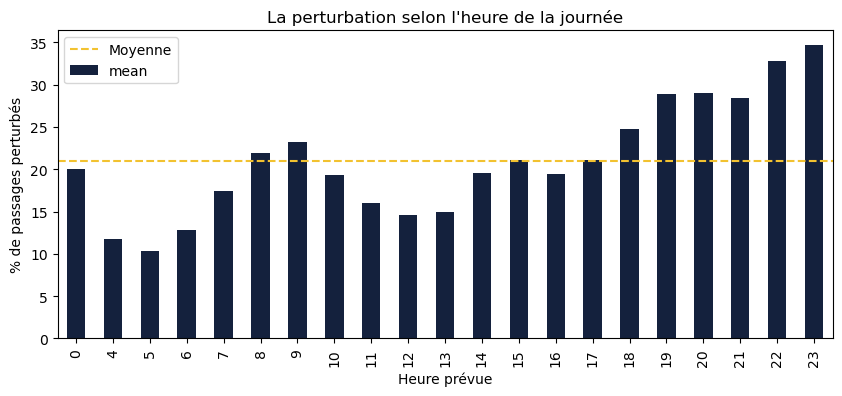

In [12]:
import matplotlib.pyplot as plt

par_heure = df_ter.groupby("heure")["perturbe"].agg(["mean", "count"])
par_heure["mean"] = par_heure["mean"] * 100

par_heure["mean"].plot(kind="bar", figsize=(10, 4), color="#14213D")
plt.axhline(df_ter["perturbe"].mean() * 100, color="#F2C230", linestyle="--", label="Moyenne")
plt.ylabel("% de passages perturbés")
plt.xlabel("Heure prévue")
plt.title("La perturbation selon l'heure de la journée")
plt.legend()
plt.show()



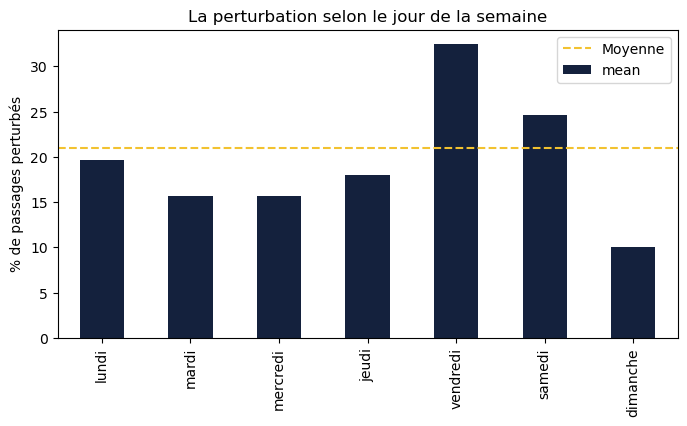

,mean,count
lundi,19.7,17529
mardi,15.7,20232
mercredi,15.7,20254
jeudi,18.0,20689
vendredi,32.4,27384
samedi,24.7,9184
dimanche,10.0,4245


In [13]:
noms = ["lundi", "mardi", "mercredi", "jeudi", "vendredi", "samedi", "dimanche"]

par_jour = df_ter.groupby("jour_semaine")["perturbe"].agg(["mean", "count"])
par_jour["mean"] = par_jour["mean"] * 100
par_jour.index = noms

par_jour["mean"].plot(kind="bar", figsize=(8, 4), color="#14213D")
plt.axhline(df_ter["perturbe"].mean() * 100, color="#F2C230", linestyle="--", label="Moyenne")
plt.ylabel("% de passages perturbés")
plt.title("La perturbation selon le jour de la semaine")
plt.legend()
plt.show()

par_jour.round(1)

In [14]:
print(df_ter.groupby("jour_semaine")["date"].nunique())

par_date = df_ter.groupby("date")[["perturbe", "supprime"]].mean() * 100
par_date.round(1)

jour_semaine
0    2
1    2
2    2
3    3
4    3
5    3
6    2
Name: date, dtype: int64


,perturbe,supprime
date,,
2026-10-08,25.7,5.1
2026-10-09,17.1,3.2
2026-10-10,9.7,0.0
2026-10-11,9.7,0.0
2026-10-12,17.5,1.7
2026-10-13,15.2,2.0
2026-10-14,12.2,0.6
2026-10-15,15.6,1.5
2026-10-16,17.2,2.3


Passages rangés : 119517 sur 119517


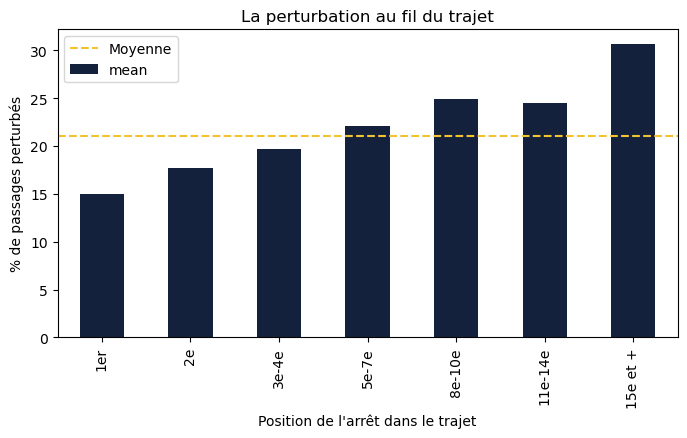

,mean,count
position,,
1er,15.0,13117
2e,17.8,14042
3e-4e,19.7,28457
5e-7e,22.1,34318
8e-10e,24.9,18556
11e-14e,24.5,8971
15e et +,30.6,2056


In [15]:
df_ter["rang"] = df_ter["ordre_arret"] + 1

tranches = [0, 1, 2, 4, 7, 10, 14, 100]
noms_tranches = ["1er", "2e", "3e-4e", "5e-7e", "8e-10e", "11e-14e", "15e et +"]
df_ter["position"] = pd.cut(df_ter["rang"], bins=tranches, labels=noms_tranches)

par_position = df_ter.groupby("position", observed=True)["perturbe"].agg(["mean", "count"])
par_position["mean"] = par_position["mean"] * 100
print("Passages rangés :", par_position["count"].sum(), "sur", len(df_ter))

par_position["mean"].plot(kind="bar", figsize=(8, 4), color="#14213D")
plt.axhline(df_ter["perturbe"].mean() * 100, color="#F2C230", linestyle="--", label="Moyenne")
plt.ylabel("% de passages perturbés")
plt.xlabel("Position de l'arrêt dans le trajet")
plt.title("La perturbation au fil du trajet")
plt.legend()
plt.show()

par_position.round(1)

In [16]:
print(df_ter["ordre_arret"].min(), df_ter["ordre_arret"].max())
print(df_ter["ordre_arret"].isna().sum())
print((df_ter["ordre_arret"] == 0).sum())

0.0 21.0
0
13117


Passages rangés : 119517 sur 119517


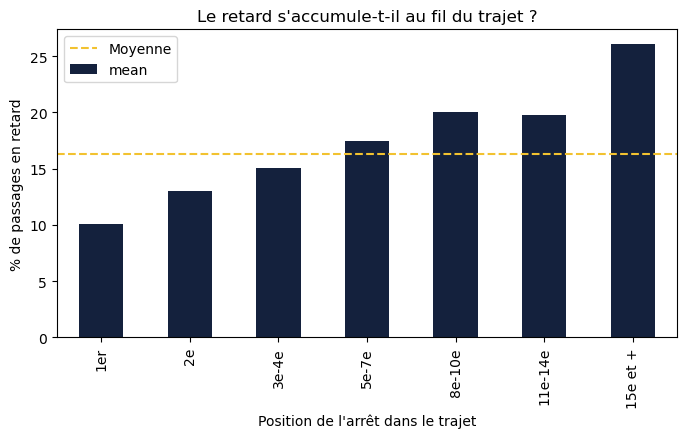

,mean,count
position,,
1er,10.1,13117
2e,13.0,14042
3e-4e,15.1,28457
5e-7e,17.5,34318
8e-10e,20.0,18556
11e-14e,19.8,8971
15e et +,26.1,2056


In [17]:
df_ter["rang"] = df_ter["ordre_arret"] + 1

tranches = [0, 1, 2, 4, 7, 10, 14, 100]
noms_tranches = ["1er", "2e", "3e-4e", "5e-7e", "8e-10e", "11e-14e", "15e et +"]
df_ter["position"] = pd.cut(df_ter["rang"], bins=tranches, labels=noms_tranches)

par_position = df_ter.groupby("position", observed=True)["en_retard"].agg(["mean", "count"])
par_position["mean"] = par_position["mean"] * 100
print("Passages rangés :", par_position["count"].sum(), "sur", len(df_ter))

par_position["mean"].plot(kind="bar", figsize=(8, 4), color="#14213D")
plt.axhline(df_ter["en_retard"].mean() * 100, color="#F2C230", linestyle="--", label="Moyenne")
plt.ylabel("% de passages en retard")
plt.xlabel("Position de l'arrêt dans le trajet")
plt.title("Le retard s'accumule-t-il au fil du trajet ?")
plt.legend()
plt.show()

par_position.round(1)

In [18]:
#le retard par rapport à la lignes 
par_ligne = df_ter.groupby(["ligne", "nom_ligne"])["perturbe"].agg(["mean", "count"])
par_ligne["mean"] = par_ligne["mean"] * 100
par_ligne = par_ligne[par_ligne["count"] >= 500].sort_values("mean", ascending=False)
print(len(par_ligne), "lignes avec au moins 500 passages")

df_ter["famille"] = df_ter["ligne"].str[0]
print((df_ter.groupby("famille")["perturbe"].mean() * 100).round(1))

par_ligne.round(1)

52 lignes avec au moins 500 passages
famille
C    23.3
K    23.2
P    17.7
Name: perturbe, dtype: float64


,,mean,count
ligne,nom_ligne,,
K16,Calais Paris,45.5,1199
C12,Paris Nord - Creil,35.8,632
C14,Compiègne Paris,35.6,2260
K45,Lille - Amiens - Abancourt - (Rouen Rive-Droite),35.0,557
C10,Paris Nord - Amiens,34.5,1831
K40,Lille Flandres - St Quentin,34.4,2257
C40,Lille Flandres - Douai,31.3,5025
K44,Lille Flandres - Amiens,31.2,1594
K10,Paris Nord - Amiens,30.9,1135


In [19]:
#Analyse par rapport à la meteo
passage_sans_plui=df_ter['pluie_mm'].isna().mean()*100
print(passage_sans_plui)
meteo=df_ter.dropna(subset=["pluie_mm", "rafales_kmh"]).copy()
meteo['pluie']=pd.cut(meteo['pluie_mm'],bins=[-1, 0, 0.5, 2, 100],labels=["sec", "bruine", "pluie", "forte pluie"])
meteo['vent']=pd.cut(meteo['rafales_kmh'],bins=[-1, 30, 50, 70, 200],labels=["calme", "modéré", "fort", "très fort"])
print((meteo.groupby("pluie", observed=True)["en_retard"].agg(["mean", "count"]) * [100, 1]).round(1))
print((meteo.groupby("vent", observed=True)["en_retard"].agg(["mean", "count"]) * [100, 1]).round(1))

0.24096990386304876
             mean  count
pluie                   
sec          15.6  94526
bruine       16.5  17110
pluie        21.3   5586
forte pluie  31.4   2007
           mean  count
vent                  
calme      15.5  73243
modéré     16.9  33521
fort       18.5   8177
très fort  19.7   4288


In [20]:
K = 20

def lisser(retards, passages, a_priori, k=K):
    return (retards + k * a_priori) / (passages + k)

# Seulement les journées complètes : à partir du 13 octobre
apprentissage = df_ter[(df_ter["date"] >= "2026-10-13") & (df_ter["date"] <= "2026-10-18")]
test = df_ter[(df_ter["date"] >= "2026-10-19") & (df_ter["date"] <= "2026-10-22")].copy()
print(f"Apprentissage : {len(apprentissage)} passages · Test : {len(test)} passages")
print(f"Perturbés : {apprentissage['perturbe'].mean():.1%} en apprentissage, {test['perturbe'].mean():.1%} en test")

# A · Le même chiffre pour tous
p_global = apprentissage["perturbe"].mean()
test["A_global"] = p_global

# B · Le taux de la ligne
par_ligne = apprentissage.groupby("ligne")["perturbe"].agg(["sum", "count"])
par_ligne["p"] = lisser(par_ligne["sum"], par_ligne["count"], p_global)
test["B_ligne"] = test["ligne"].map(par_ligne["p"]).fillna(p_global)

# C · Le calcul du site
par_heure = apprentissage.groupby("heure")["perturbe"].agg(["sum", "count"])
par_heure["p"] = lisser(par_heure["sum"], par_heure["count"], p_global)
ligne_heure = apprentissage.groupby(["ligne", "heure"])["perturbe"].agg(["sum", "count"]).reset_index()
ligne_heure["a_priori"] = ligne_heure["heure"].map(par_heure["p"]).fillna(p_global)
ligne_heure["p_lh"] = lisser(ligne_heure["sum"], ligne_heure["count"], ligne_heure["a_priori"])
test = test.merge(ligne_heure[["ligne", "heure", "p_lh"]], on=["ligne", "heure"], how="left")
test["p_lh"] = test["p_lh"].fillna(test["heure"].map(par_heure["p"])).fillna(p_global)
par_train = apprentissage.groupby("numero_train")["perturbe"].agg(["sum", "count"])
test["C_site"] = lisser(test["numero_train"].map(par_train["sum"]).fillna(0),
                        test["numero_train"].map(par_train["count"]).fillna(0), test["p_lh"])

# Les scores
resultats = pd.DataFrame({
    "Score de Brier": [((test[c] - test["perturbe"]) ** 2).mean() for c in ["A_global", "B_ligne", "C_site"]],
}, index=["A · Le même chiffre pour tous", "B · Le taux de la ligne", "C · Le calcul du site"])
resultats["Gain sur A"] = (1 - resultats["Score de Brier"] / resultats["Score de Brier"].iloc[0]) * 100
resultats.round(4)

Apprentissage : 48836 passages · Test : 40387 passages
Perturbés : 14.9% en apprentissage, 19.2% en test


,Score de Brier,Gain sur A
A · Le même chiffre pour tous,0.1570,0.0000
B · Le taux de la ligne,0.1563,0.4404
C · Le calcul du site,0.1600,-1.9298


In [21]:
print(f"Perturbés en apprentissage : {apprentissage['perturbe'].mean():.1%}")
print(f"Perturbés en test          : {test['perturbe'].mean():.1%}")
print(f"Passages par jour          : {len(apprentissage) / 11:.0f} en apprentissage, {len(test) / 4:.0f} en test")

Perturbés en apprentissage : 14.9%
Perturbés en test          : 19.2%
Passages par jour          : 4440 en apprentissage, 10097 en test


In [22]:
passages_par_jour = df_ter.groupby("date").size()
passages_par_jour.index = passages_par_jour.index.strftime("%a %d/%m")
passages_par_jour

date
Thu 08/10      432
Fri 09/10     8257
Sat 10/10     2586
Sun 11/10      825
Mon 12/10     7448
Tue 13/10    10134
Wed 14/10    10151
Thu 15/10    10152
Fri 16/10    10143
Sat 17/10     4836
Sun 18/10     3420
Mon 19/10    10081
Tue 20/10    10098
Wed 21/10    10103
Thu 22/10    10105
Fri 23/10     8984
Sat 24/10     1762
dtype: int64